# 04: RAFT + geometria rolling shutter (ruch kamery i obiektów)

1. **RAFT** (gotowe wagi) znajduje dla każdego piksela obrazu A, gdzie ten sam punkt jest w obrazie B.
2. **Geometria** (bez uczenia): z przesunięcia i znanej różnicy czasu odczytu liczy prędkość każdego piksela,
   a z niej obraz w chwili docelowej.
3. **Dostrajanie**: uczy się tylko RAFT, z błędu obrazu wynikowego względem wzorca.
4. **Demo** na parze zdjęć z kamer (wiatrak).

**Dane:** zbiór z nagrań X4K (`src/synth_video.py`) spakowany jako `MyDrive/rs_project/datasets/rs_video_x4k.zip`.

In [1]:
# === SETUP: uruchamiaj zawsze jako pierwszą komórkę ===
# Kod jest pobierany z GitHuba na maszynę Colaba (lokalne pliki z VS Code tam nie trafiają).
# Po zmianie kodu: commit + push w VS Code, potem ponownie ta komórka (robi git pull).
REPO = 'kordiusz/RollingShutter'   # repozytorium na GitHubie
BRANCH = 'main'

import os, sys, subprocess, getpass, importlib
from google.colab import drive
drive.mount('/content/drive')

TOKEN_FILE = '/content/drive/MyDrive/rs_project/.github_token'   # opcjonalnie: token zapisany na Drive
CODE = '/content/code'

def _git(*args):
    r = subprocess.run(['git', *args], capture_output=True, text=True)
    if r.returncode != 0:
        msg = (r.stderr or r.stdout).replace(token, '***') if 'token' in globals() else r.stderr
        raise RuntimeError('git ' + args[0] + ' nie powiodło się:\n' + msg)
    return r.stdout

if not os.path.exists(CODE):
    token = (open(TOKEN_FILE).read().strip() if os.path.exists(TOKEN_FILE)
             else getpass.getpass('GitHub token (fine-grained, tylko odczyt): '))
    _git('clone', '-q', '-b', BRANCH, f'https://{token}@github.com/{REPO}.git', CODE)
else:
    _git('-C', CODE, 'pull', '-q')
os.chdir(CODE)
sys.path.insert(0, f'{CODE}/src')
import project_paths as P
importlib.reload(P)
P.ensure_dirs()
print(_git('log', '-1', '--format=kod: %h  %s  (%cd)', '--date=short'))
!nvidia-smi --query-gpu=name,memory.total --format=csv,noheader

Mounted at /content/drive
kod: 1229dc2  raft  (2026-10-24)

NVIDIA L4, 23034 MiB


## 1. Zbiór danych (rozpakowanie z Drive na dysk maszyny Colaba)

In [2]:
import os, glob
DATASET_NAME = 'rs_video_x4k'
z = P.find_dataset_zip(DATASET_NAME)
assert z, f'Brak {DATASET_NAME}.zip w {P.DATASETS} - wrzuć tam spakowany folder data/{DATASET_NAME}'
UNZ = f'/content/unz_{DATASET_NAME}'
if not os.path.exists(UNZ):
    print('rozpakowuję', z, '...')
    !unzip -q "{z}" -d "{UNZ}"
# folder z podfolderami train/ i val/ (niezależnie od tego, jak spakowano)
DATA = next(os.path.dirname(p) for p in sorted(glob.glob(f'{UNZ}/**/train', recursive=True)))
print('DATA =', DATA, '|', len(os.listdir(f'{DATA}/train')), 'train /', len(os.listdir(f'{DATA}/val')), 'val')
WORKERS = min(8, os.cpu_count())

rozpakowuję /content/drive/MyDrive/rs_project/datasets/rs_video_x4k.zip ...
DATA = /content/unz_rs_video_x4k/rs_video_x4k | 2397 train / 321 val


## 2. Bez treningu: gotowy RAFT + geometria
Wynik odniesienia. `psnr` = wynik, `psnr_in` = bez korekcji (wejście RS A). Liczone tam, gdzie piksel źródłowy jest w kadrze A.

device: cuda
Downloading: "https://download.pytorch.org/models/raft_large_C_T_SKHT_V2-ff5fadd5.pth" to /root/.cache/torch/hub/checkpoints/raft_large_C_T_SKHT_V2-ff5fadd5.pth
100% 20.1M/20.1M [00:00<00:00, 153MB/s]
        psnr: 32.8569
        ssim: 0.9359
     psnr_in: 26.4165
     ssim_in: 0.7952
       valid: 0.9798
 ms_per_pair: 24.0618
saved /content/drive/MyDrive/rs_project/runs/2026-10-24_raft_zeroshot/eval.json and /content/drive/MyDrive/rs_project/runs/2026-10-24_raft_zeroshot/preview_eval.png
kolumny: RS A | RS B | wynik | wzorzec | przepływ RAFT A->B | pewność geometrii | błąd


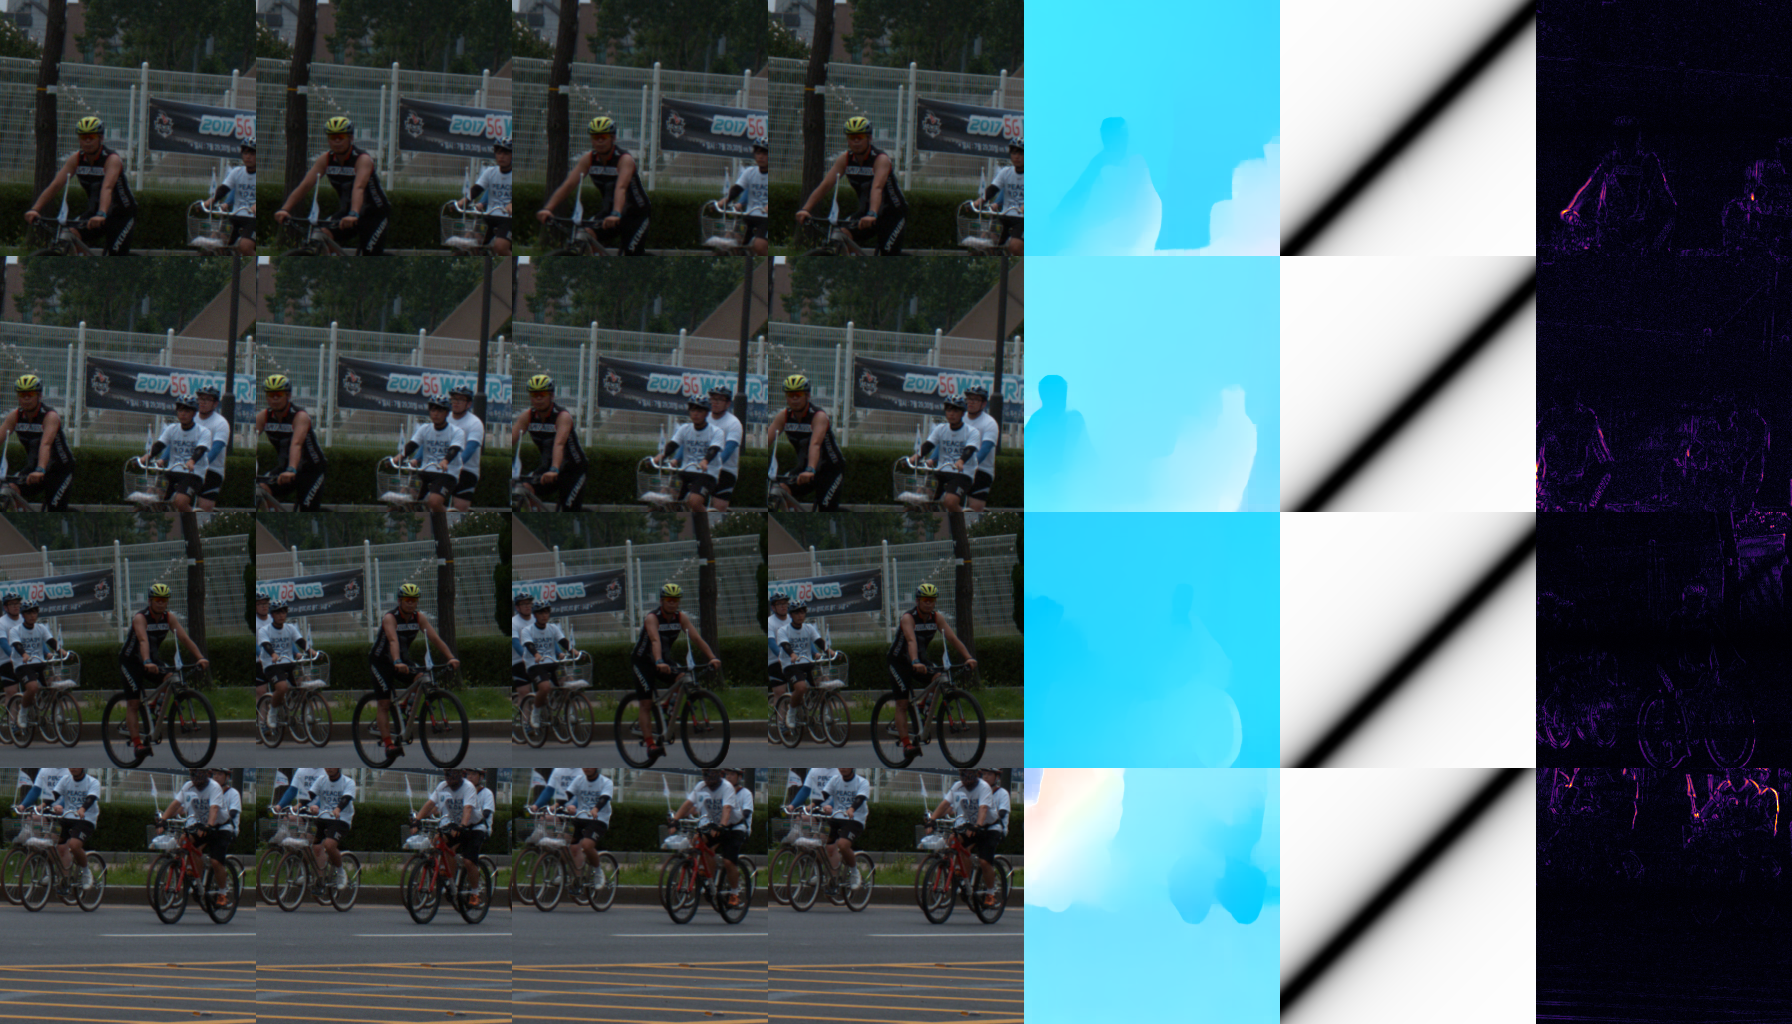

In [3]:
from datetime import date
from IPython.display import Image, display
ZS = f'{date.today()}_raft_zeroshot'
!python src/train_raft.py --data "{DATA}" --zero-shot --bs 8 --workers {WORKERS} --out "{P.RUNS}" --name {ZS}
print('kolumny: RS A | RS B | wynik | wzorzec | przepływ RAFT A->B | pewność geometrii | błąd')
display(Image(str(P.RUNS / ZS / 'preview_eval.png')))

## 3. Dostrajanie RAFT (geometria stała)
Na A100/L4 jedna epoka to kilka minut. Checkpoint co epokę na Drive (`runs/<data>_raft_geom/`).

In [4]:
RUN = f'{date.today()}_raft_geom'
!python src/train_raft.py --data "{DATA}" --epochs 10 --bs 8 --lr 2e-5 --workers {WORKERS} --out "{P.RUNS}" --name {RUN}

device: cuda
before fine-tuning (pretrained): val PSNR 32.86 dB (input 26.42)
ep   1/10 loss 0.0122 | val PSNR 33.72 dB (input 26.43) SSIM 0.9392 (input 0.7953) | 108s
ep   2/10 loss 0.0119 | val PSNR 33.96 dB (input 26.42) SSIM 0.9400 (input 0.7953) | 108s
ep   3/10 loss 0.0118 | val PSNR 34.10 dB (input 26.43) SSIM 0.9403 (input 0.7953) | 108s
ep   4/10 loss 0.0117 | val PSNR 34.19 dB (input 26.43) SSIM 0.9406 (input 0.7953) | 108s
ep   5/10 loss 0.0116 | val PSNR 34.24 dB (input 26.43) SSIM 0.9409 (input 0.7953) | 108s
ep   8/10 loss 0.0115 | val PSNR 34.30 dB (input 26.43) SSIM 0.9411 (input 0.7953) | 108s
ep   9/10 loss 0.0115 | val PSNR 34.30 dB (input 26.43) SSIM 0.9411 (input 0.7953) | 108s
ep  10/10 loss 0.0115 | val PSNR 34.30 dB (input 26.43) SSIM 0.9411 (input 0.7953) | 108s
done. best val PSNR 34.30 dB -> /content/drive/MyDrive/rs_project/runs/2026-10-24_raft_geom/best.pt


,psnr,ssim,psnr_in,ssim_in,valid,ms_per_pair
run,,,,,,
2026-10-24_raft_zeroshot,32.857,0.936,26.417,0.795,0.980,24.062
2026-10-24_raft_geom,34.300,0.941,26.426,0.795,0.979,18.155


/content/drive/MyDrive/rs_project/runs/2026-10-24_raft_geom/preview_ep10.png


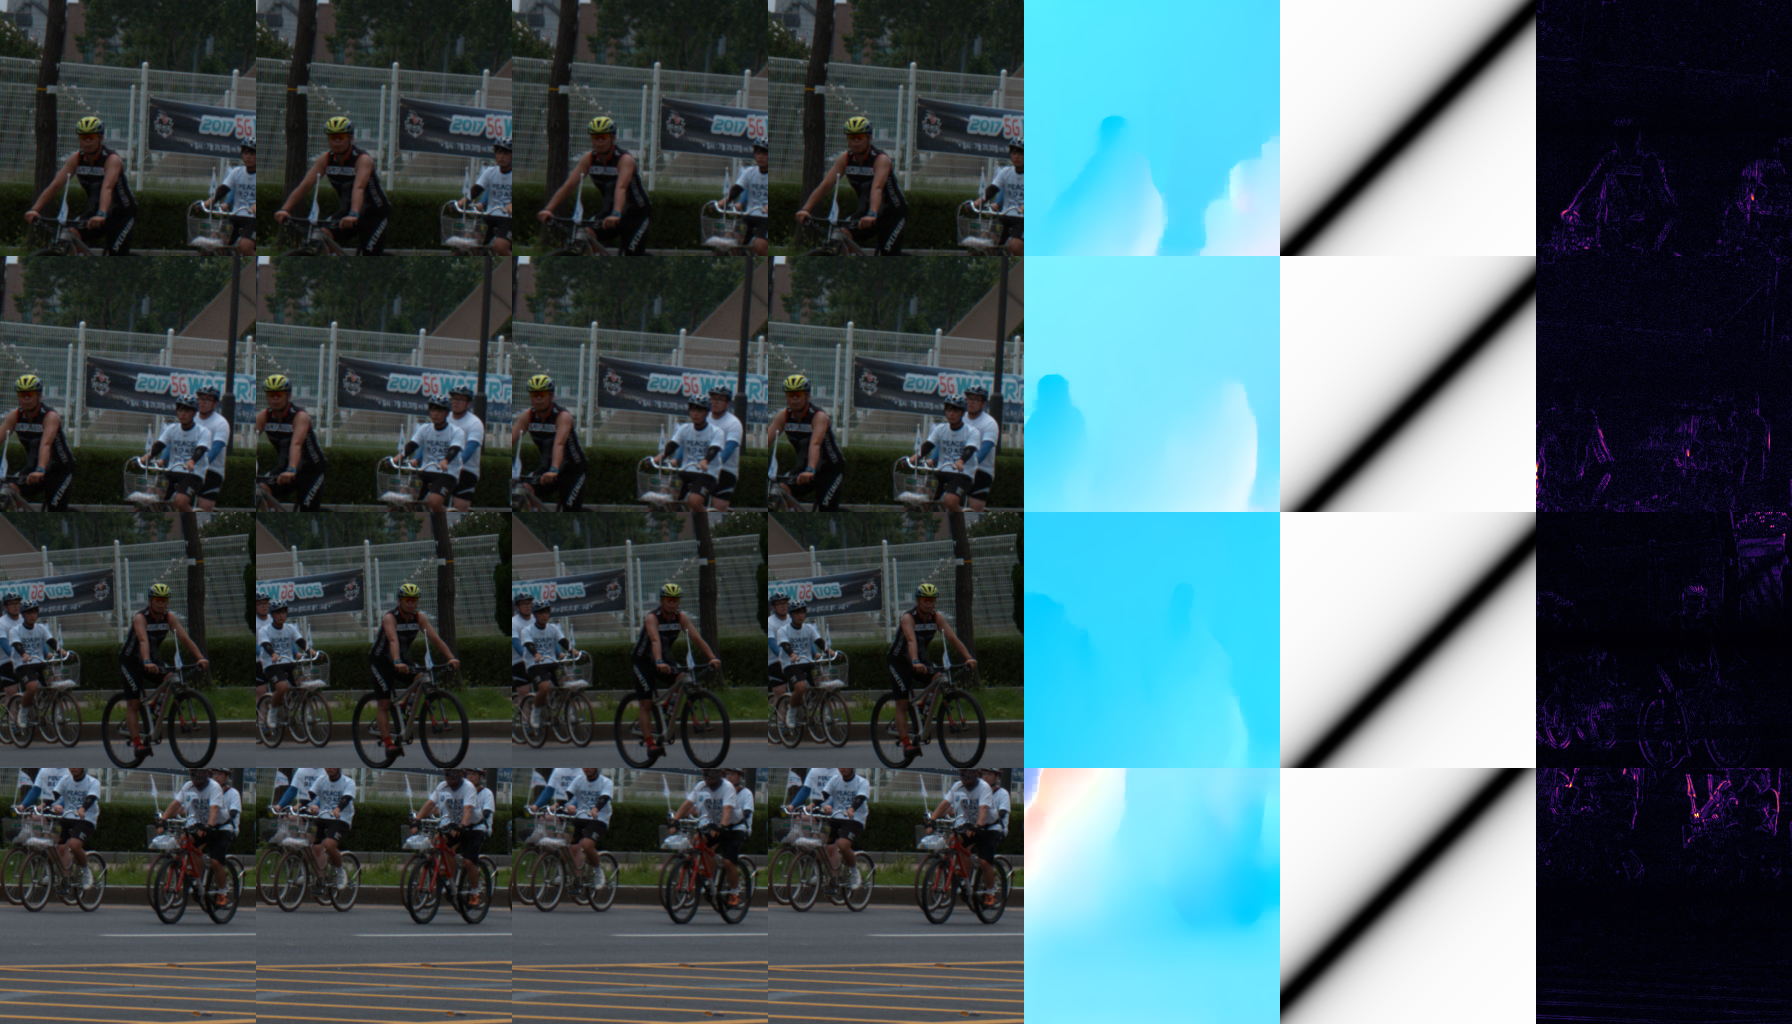

In [5]:
import json, pandas as pd
rows = []
for name, ck in [(ZS, None), (RUN, P.RUNS / RUN / 'best.pt')]:
    ej = P.RUNS / name / 'eval.json'
    if ck is not None:
        !python src/train_raft.py --data "{DATA}" --eval "{ck}" --eval-json "{ej}" --bs 8 --workers {WORKERS} --out "{P.RUNS}" > /dev/null
    m = json.load(open(ej))['metrics']
    rows.append({'run': name, **{k: round(v, 3) for k, v in m.items()}})
display(pd.DataFrame(rows).set_index('run'))
p = sorted((P.RUNS / RUN).glob('preview_ep*.png'))[-1]
print(p); display(Image(str(p)))

## 4. DEMO: wiatrak (para zdjęć z kamer)

1. Wrzuć zdjęcia na Drive do **`MyDrive/rs_project/real/wiatrak/`** jako `kamera_A.jpg` i `kamera_B.jpg`
   (tak, jak zapisały je kamery: obraz z B jest obrócony o 90°).
2. Uruchom komórkę poniżej. Pierwszy obrazek: całe zdjęcia z zaznaczonymi wycinkami 256×256.
   **Obraz B (po prawej) musi stać „prosto” jak A**; jeśli jest do góry nogami, zmień `ROT_K` na `-1`.
3. Ustaw `CENTER_A` na środek wiatraka w obrazie A (piksele), jeśli wycinek go nie obejmuje.

Kamery USB nie są zsynchronizowane, więc nie znamy przesunięcia startu klatek. Dlatego wynik liczony jest
dla kilku wartości (`SYNC_SWEEP`); wybierz tę, przy której łopaty wyglądają najprościej.
To wynik jakościowy: przy bardzo szybkim obrocie (dużo ponad 1/8 obrotu na klatkę) założenie ruchu po prostej przestaje działać.

A (1920, 1080, 3) | B (1920, 1080, 3) | model: /content/drive/MyDrive/rs_project/runs/2026-10-24_raft_geom/best.pt
wycinek A: środek [540. 865.] (przesunięty do obszaru widocznego w obu kamerach) | przesunięcie widoków [-51.7 123.4] px | resztkowe [-13.83 -17.73] px | odczyt wycinka 16.0 ms, sync środków +2.3 ms


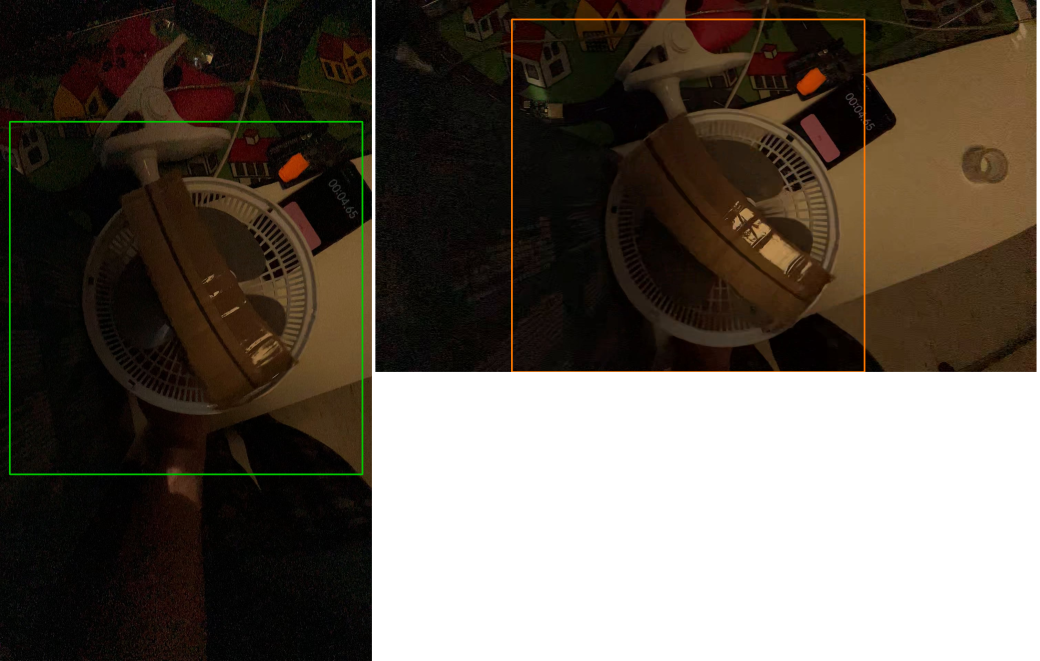

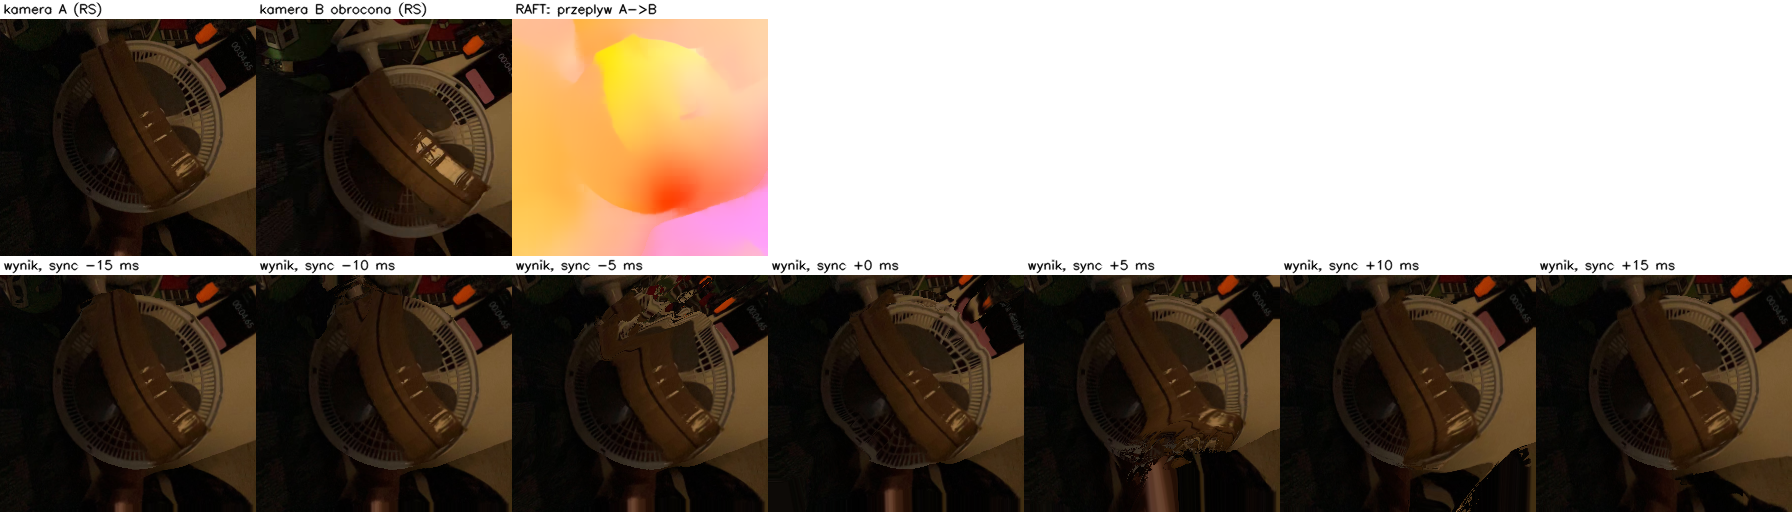

zapisano w /content/drive/MyDrive/rs_project/results/demo_wiatrak


In [12]:
import cv2, torch, numpy as np
import demo_real, raft_geom
importlib.reload(raft_geom); importlib.reload(demo_real)
from demo_real import prepare_pair, run_pair, figure, overview
from raft_geom import load_raft_geom

REAL = P.ROOT / 'real' / 'wiatrak'
IMG_A = sorted(REAL.glob('kamera_A.*'))[0]
IMG_B = sorted(REAL.glob('kamera_B.*'))[0]
ROT_K = 1               # 1 albo -1: kierunek obrotu kamery B (sprawdź na podglądzie)
CENTER_A = None           # (x, y) środek wycinka w obrazie A, np. środek wiatraka; None = środek obrazu
SIDE = 1024                # wycinek w pikselach oryginalnego zdjęcia (256 = bez skalowania)
T_FULL_MS = 30.0          # czas odczytu całej klatki [ms] (typowo ~30 ms dla kamer USB; do zmierzenia)
SYNC_SWEEP = [-15, -10, -5, 0, 5, 10, 15]   # testowane przesunięcia startu kamery B [ms]

CKPT = P.find_run('raft_geom')              # dostrojony model z sekcji 3, jeśli jest
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
model = load_raft_geom(str(CKPT) if CKPT else None, dev, rot_k=ROT_K); model.rot_k = ROT_K
img_a, img_b = cv2.imread(str(IMG_A)), cv2.imread(str(IMG_B))
print('A', img_a.shape, '| B', img_b.shape, '| model:', CKPT or 'gotowy RAFT (bez dostrajania)')

pair = prepare_pair(img_a, img_b, ROT_K, CENTER_A, SIDE, 256, T_FULL_MS)
d, outs = run_pair(model, pair, SYNC_SWEEP, dev, base='static')
print(f"wycinek A: środek {np.round(pair['center_a'], 0)}"
      + (' (przesunięty do obszaru widocznego w obu kamerach)' if pair['center_moved'] else '')
      + f" | przesunięcie widoków {np.round(pair['shift'], 1)} px | resztkowe {np.round(pair['base_used'], 2)} px"
      + f" | odczyt wycinka {pair['T']:.1f} ms, sync środków {pair['sync']:+.1f} ms")
OUT = P.RESULTS / 'demo_wiatrak'; OUT.mkdir(parents=True, exist_ok=True)
cv2.imwrite(str(OUT / 'podglad.png'), overview(img_a, pair))
cv2.imwrite(str(OUT / 'wynik.png'), figure(pair, d, outs))
display(Image(str(OUT / 'podglad.png')))
display(Image(str(OUT / 'wynik.png')))
print('zapisano w', OUT)